## Доступные GPU

In [3]:
import csv
import io
import subprocess

fields = ["index", "name", "memory.total", "memory.used", "utilization.gpu", "temperature.gpu"]

result = subprocess.run(
    ["nvidia-smi", f"--query-gpu={','.join(fields)}", "--format=csv,noheader"],
    capture_output=True,
    text=True,
    check=True,
    timeout=15,
)

for row in csv.reader(io.StringIO(result.stdout), skipinitialspace=True):
    gpu = dict(zip(fields, row))

    print(f"GPU {gpu['index']}: {gpu['name']}")
    print(f"  Память:     {gpu['memory.used']} / {gpu['memory.total']}")
    print(f"  Загрузка:   {gpu['utilization.gpu']}")
    print(f"  Температура: {gpu['temperature.gpu']} °C")
    print()

GPU 0: NVIDIA RTX A4000
  Память:     6588 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 30 °C

GPU 1: NVIDIA RTX A4000
  Память:     13773 MiB / 16376 MiB
  Загрузка:   72 %
  Температура: 43 °C

GPU 2: NVIDIA RTX A4000
  Память:     10746 MiB / 16376 MiB
  Загрузка:   38 %
  Температура: 49 °C

GPU 3: NVIDIA RTX A4000
  Память:     12444 MiB / 16376 MiB
  Загрузка:   0 %
  Температура: 42 °C

GPU 4: NVIDIA RTX A4000
  Память:     15629 MiB / 16376 MiB
  Загрузка:   69 %
  Температура: 65 °C

GPU 5: NVIDIA RTX A4000
  Память:     3511 MiB / 16376 MiB
  Загрузка:   2 %
  Температура: 32 °C

GPU 6: NVIDIA RTX A4000
  Память:     15869 MiB / 16376 MiB
  Загрузка:   85 %
  Температура: 66 °C



## Импорты и параметры

In [4]:
%matplotlib inline

import os
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "common").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import torch

import cute_rmsnorm
import triton_rmsnorm
from common.asm import dump_asm
from common.inputs import make_inputs
from common.run import make_runner, run_benchmark
from neuroslop.visualize_bench_results import plot_benchmark

device = torch.device("cuda:0")
torch.cuda.set_device(device)
major, minor = torch.cuda.get_device_capability(device)
os.environ["TORCH_CUDA_ARCH_LIST"] = f"{major}.{minor}+PTX"

M, N = 4096, 4096
EPS = cute_rmsnorm.EPS
DTYPE = torch.float32
SEED = 42
RTOL = 1e-5
ATOL = 1e-6


def make_rmsnorm_inputs(rows, cols):
    return make_inputs(
        (rows, cols), (cols,), dtype=DTYPE, seed=SEED, device=device
    )


def rms_norm(x, weight):
    return torch.nn.functional.rms_norm(x, (x.shape[-1],), weight, eps=EPS)


def rms_norm_ops(x, weight):
    inv_rms = torch.rsqrt(x.square().mean(dim=-1, keepdim=True) + EPS)
    return x * inv_rms * weight

## Реализации

In [5]:
# Добавь имя готового ядра, чтобы включить его в проверку, замер и экспорт.
ENABLED_BACKENDS = ("torch", "torch_compile", "cute", "cuda", "cuda_shfl")

runners = {
    "torch": make_runner("torch", rms_norm),
    "torch_compile": make_runner("torch_compile", rms_norm_ops),
    "triton": make_runner(
        "triton", triton_rmsnorm.rms_norm_kernel,
        extra_args=lambda x, weight, out: (x.stride(0), x.shape[1], EPS),
        grid=lambda meta: (meta["x_ptr"].shape[0],),
    ),
    "cute": make_runner("cute", cute_rmsnorm.rms_norm(autotune=False)),
    "cuda": make_runner("cuda", "cuda_rmsnorm.cu", entry="rms_norm"),
    "cuda_shfl": make_runner("cuda", "cuda_shfl_rmsnorm.cu", entry="rms_norm"),
}
implementations = {name: runners[name] for name in ENABLED_BACKENDS}

## Проверка корректности


In [6]:
for rows, cols in [(1, 1), (3, 7), (5, 255), (2, 256), (3, 257), (7, 1000),
                   (4, 4096), (3, 8196), (M, N)]:
    inputs = make_rmsnorm_inputs(rows, cols)
    expected = rms_norm(*inputs)
    for name, fn in implementations.items():
        torch.testing.assert_close(
            fn(*inputs), expected, rtol=RTOL, atol=ATOL,
            msg=lambda error: f"{name}, {rows}x{cols}\n{error}",
        )
print("OK")

/home/babanovil/ysda-dsl/.venv/lib/python3.12/site-packages/torch/_dynamo/pgo.py:605: UserWarning: dynamo_pgo force disabled by torch.compiler.config.force_disable_caches
  warn_once(


KeyboardInterrupt: 

## Бенчмарк

ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
ass
         torch: 514.048 us (p20-p80: 513.024-515.072) | 0.130550 TFLOP/s | 261.13 GB/s | 0.73x
 torch_compile: 376.832 us (p20-p80: 375.603-378.880) | 0.178087 TFLOP/s | 356.22 GB/s | 1.00x
          cute: 344.064 us (p20-p80: 343.040-344.064) | 0.195048 TFLOP/s | 390.14 GB/s | 1.10x
          cuda: 504.832 us (p20-p80: 502.886-506.880) | 0.132933 TFLOP/s | 265.90 GB/s | 0.75x
     cuda_shfl: 348.160 us (p20-p80: 347.994-349.184) | 0.192753 TFLOP/s | 385.55 GB/s | 1.08x


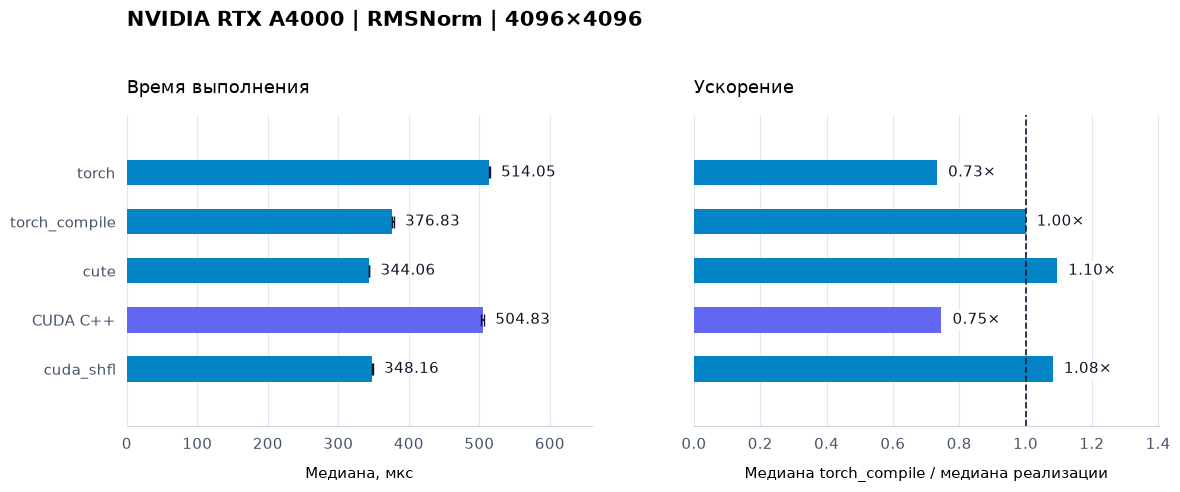

In [7]:
inputs = make_rmsnorm_inputs(M, N)
# На элемент: квадрат, сложение для суммы и два умножения.
results = run_benchmark(implementations, inputs, reference=rms_norm, flops=4 * M * N)
plot_benchmark(
    results, baseline="torch_compile",
    title=f"{torch.cuda.get_device_name(device)} | RMSNorm | {M}×{N}",
)
plt.show()

## PTX и SASS

In [ ]:
for name, fn in implementations.items():
    assembly = fn.asm()
    dump_asm(assembly, Path("asm") / name)
    print(name, list(assembly))

torch []
torch_compile ['triton_poi_fused_add_mean_mul_pow_rsqrt_0', 'triton_red_fused_add_mean_mul_pow_rsqrt_0']
cute ['rms_norm']
cuda ['cuda_rmsnorm']
cuda_shfl ['cuda_shfl_rmsnorm']
